# Exploratory Data Analysis on Superstore Retail Sales

## Internship
Datheon – Data Analytics & Power BI Internship

## Objective
To perform exploratory data analysis on the Superstore Retail Sales dataset to understand sales performance, profitability, customer purchasing patterns, and business trends.

## Tools and Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

Libraries imported successfully!
Dataset loaded successfully!
  Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0      1  CA-2017-152156   11/8/2017  11/11/2017    Second Class    CG-12520   
1      2  CA-2017-152156   11/8/2017  11/11/2017    Second Class    CG-12520   
2      3  CA-2017-138688   6/12/2017   6/16/2017    Second Class    DV-13045   
3      4  US-2016-108966  10/11/2016  10/18/2016  Standard Class    SO-20335   
4      5  US-2016-108966  10/11/2016  10/18/2016  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product 

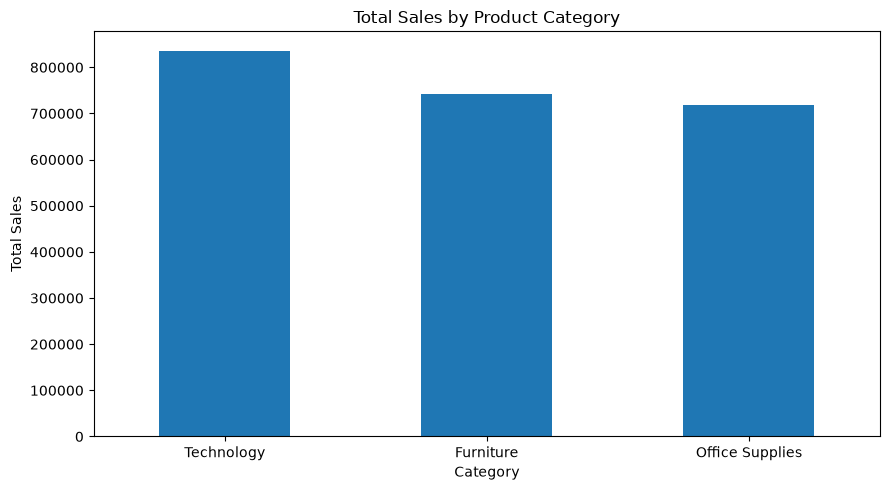

Sales by Region:
Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64
Profit by Region:
Region
West       108418.4489
East        91522.7800
South       46749.4303
Central     39706.3625
Name: Profit, dtype: float64


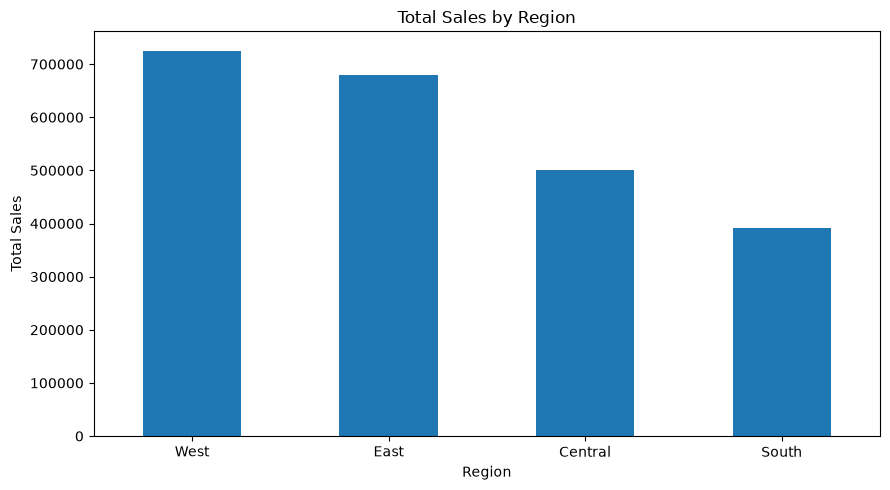

Sales by Customer Segment:
Segment
Consumer       1.161401e+06
Corporate      7.061464e+05
Home Office    4.296531e+05
Name: Sales, dtype: float64
Profit by Customer Segment:
Segment
Consumer       134119.2092
Corporate       91979.1340
Home Office     60298.6785
Name: Profit, dtype: float64


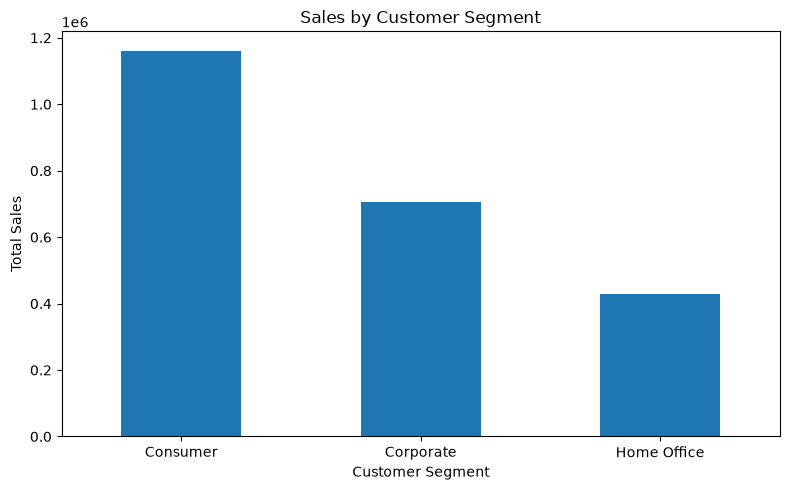

Monthly Sales:
Year-Month
2015-01     14236.8950
2015-02      4519.8920
2015-03     55691.0090
2015-04     28295.3450
2015-05     23648.2870
2015-06     34595.1276
2015-07     33946.3930
2015-08     27909.4685
2015-09     81777.3508
2015-10     31453.3930
2015-11     78628.7167
2015-12     69545.6205
2016-01     18174.0756
2016-02     11951.4110
2016-03     38726.2520
2016-04     34195.2085
2016-05     30131.6865
2016-06     24797.2920
2016-07     28765.3250
2016-08     36898.3322
2016-09     64595.9180
2016-10     31404.9235
2016-11     75972.5635
2016-12     74919.5212
2017-01     18542.4910
2017-02     22978.8150
2017-03     51715.8750
2017-04     38750.0390
2017-05     56987.7280
2017-06     40344.5340
2017-07     39261.9630
2017-08     31115.3743
2017-09     73410.0249
2017-10     59687.7450
2017-11     79411.9658
2017-12     96999.0430
2018-01     43971.3740
2018-02     20301.1334
2018-03     58872.3528
2018-04     36521.5361
2018-05     44261.1102
2018-06     52981.7257
2018-07 

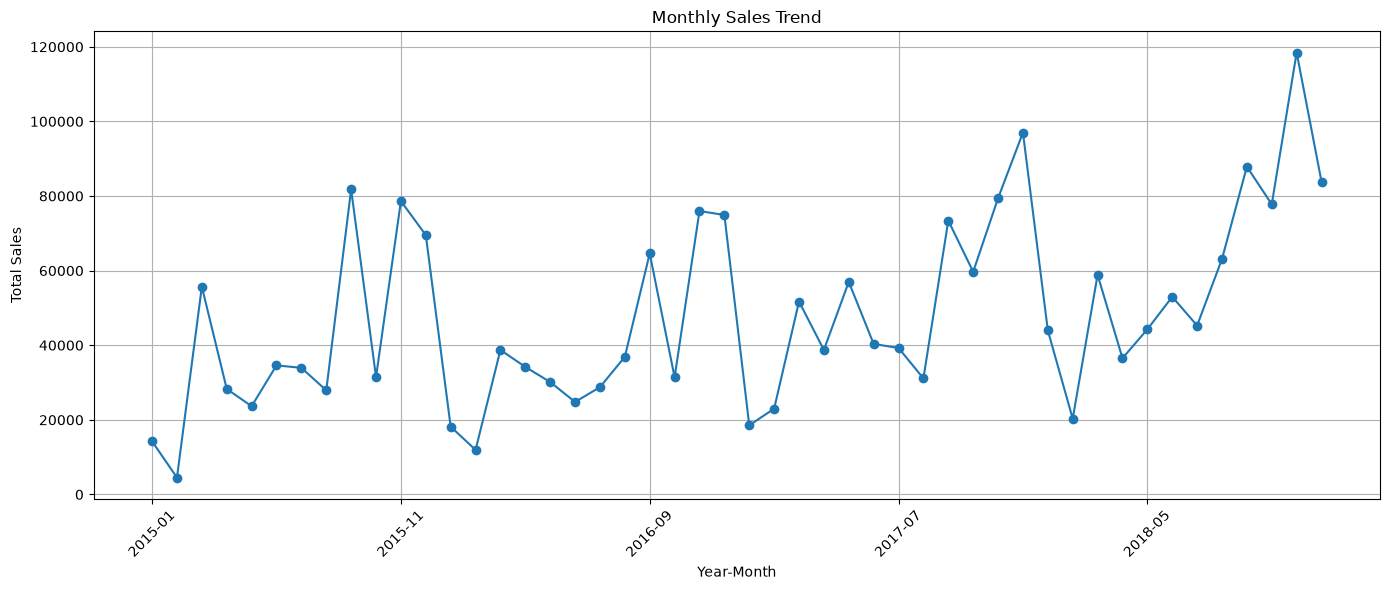

Sales by Sub-Category:
Sub-Category
Phones         330007.0540
Chairs         328449.1030
Storage        223843.6080
Tables         206965.5320
Binders        203412.7330
Machines       189238.6310
Accessories    167380.3180
Copiers        149528.0300
Bookcases      114879.9963
Appliances     107532.1610
Furnishings     91705.1640
Paper           78479.2060
Supplies        46673.5380
Art             27118.7920
Envelopes       16476.4020
Labels          12486.3120
Fasteners        3024.2800
Name: Sales, dtype: float64


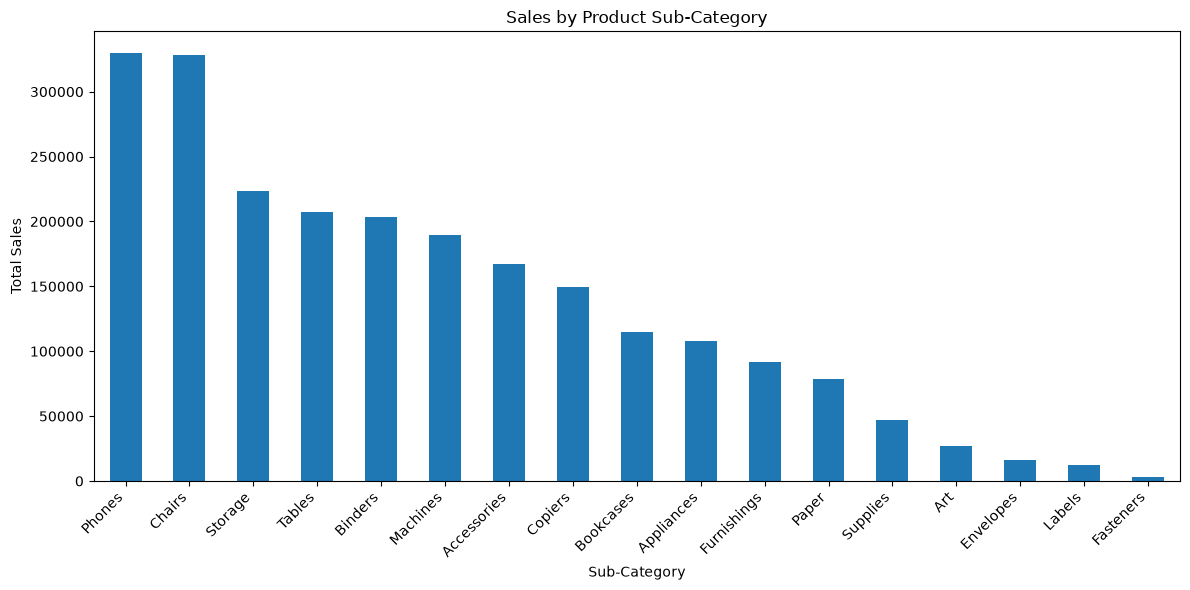

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

df = pd.read_csv("superstore_sales.csv")

print("Dataset loaded successfully!")
print(df.head())
print(df.tail())
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
print("Dataset Columns:")

for column in df.columns:
    print(column)
print(df.info())
print(df.describe(include='all'))
print("Column Data Types:")
print(df.dtypes)

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': missing_percentage
})

print(missing_summary)

duplicate_count = df.duplicated().sum()

print("Number of Duplicate Records:", duplicate_count)

df = df.drop_duplicates()

print("Duplicate records removed successfully!")
print("Updated Dataset Shape:", df.shape)

if 'Postal Code' in df.columns:
    df['Postal Code'] = df['Postal Code'].fillna('Unknown')

print("Missing Postal Codes handled successfully!")
print("Remaining Missing Values:", df.isnull().sum().sum())

date_columns = ['Order Date', 'Ship Date']

for column in date_columns:
    df[column] = pd.to_datetime(
        df[column],
        format='%m/%d/%Y',
        errors='coerce'
    )

print("Date columns converted successfully!")
print(df[date_columns].dtypes)

for column in date_columns:
    print(column, "Invalid Dates:", df[column].isnull().sum())

df['Year'] = df['Order Date'].dt.year

print("Year column created successfully!")
print(df[['Order Date', 'Year']].head())
df['Month'] = df['Order Date'].dt.month_name()

print("Month column created successfully!")
print(df[['Order Date', 'Month']].head())

df['Year-Month'] = df['Order Date'].dt.to_period('M').astype(str)

print("Year-Month column created successfully!")
print(df[['Order Date', 'Year', 'Month', 'Year-Month']].head())

print(df.head())
print("Dataset Shape:", df.shape)
print("\nDataset Information:")
print(df.info())
total_sales = df['Sales'].sum()

print("Total Sales:", round(total_sales, 2))

total_profit = df['Profit'].sum()

print("Total Profit:", round(total_profit, 2))
total_quantity = df['Quantity'].sum()

print("Total Quantity Sold:", total_quantity)
average_sales = df['Sales'].mean()
average_profit = df['Profit'].mean()

print("Average Sales:", round(average_sales, 2))
print("Average Profit:", round(average_profit, 2))
profit_margin = (total_profit / total_sales) * 100

print("Overall Profit Margin:", round(profit_margin, 2), "%")

category_sales = df.groupby('Category')['Sales'].sum().sort_values(ascending=False)

print("Sales by Category:")
print(category_sales)

category_profit = df.groupby('Category')['Profit'].sum().sort_values(ascending=False)

print("Profit by Category:")
print(category_profit)

plt.figure(figsize=(9, 5))

category_sales.plot(kind='bar')

plt.title('Total Sales by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

region_sales = df.groupby('Region')['Sales'].sum().sort_values(ascending=False)

print("Sales by Region:")
print(region_sales)

region_profit = df.groupby('Region')['Profit'].sum().sort_values(ascending=False)

print("Profit by Region:")
print(region_profit)

plt.figure(figsize=(9, 5))

region_sales.plot(kind='bar')

plt.title('Total Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

segment_sales = df.groupby('Segment')['Sales'].sum().sort_values(ascending=False)

print("Sales by Customer Segment:")
print(segment_sales)

segment_profit = df.groupby('Segment')['Profit'].sum().sort_values(ascending=False)

print("Profit by Customer Segment:")
print(segment_profit)

plt.figure(figsize=(8, 5))

segment_sales.plot(kind='bar')

plt.title('Sales by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

monthly_sales = df.groupby('Year-Month')['Sales'].sum()

print("Monthly Sales:")
print(monthly_sales)

plt.figure(figsize=(14, 6))

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Year-Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

subcategory_sales = df.groupby('Sub-Category')['Sales'].sum().sort_values(ascending=False)

print("Sales by Sub-Category:")
print(subcategory_sales)

plt.figure(figsize=(12, 6))

subcategory_sales.plot(kind='bar')

plt.title('Sales by Product Sub-Category')
plt.xlabel('Sub-Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Discount Distribution:
Discount
0.00    4798
0.10      94
0.15      52
0.20    3657
0.30     227
0.32      27
0.40     206
0.45      11
0.50      66
0.60     138
0.70     418
0.80     300
Name: count, dtype: int64
Average Profit by Discount:
Discount
0.00     66.900292
0.10     96.055074
0.15     27.288298
0.20     24.702572
0.30    -45.679636
0.32    -88.560656
0.40   -111.927429
0.45   -226.646464
0.50   -310.703456
0.60    -43.077212
0.70    -95.874060
0.80   -101.796797
Name: Profit, dtype: float64


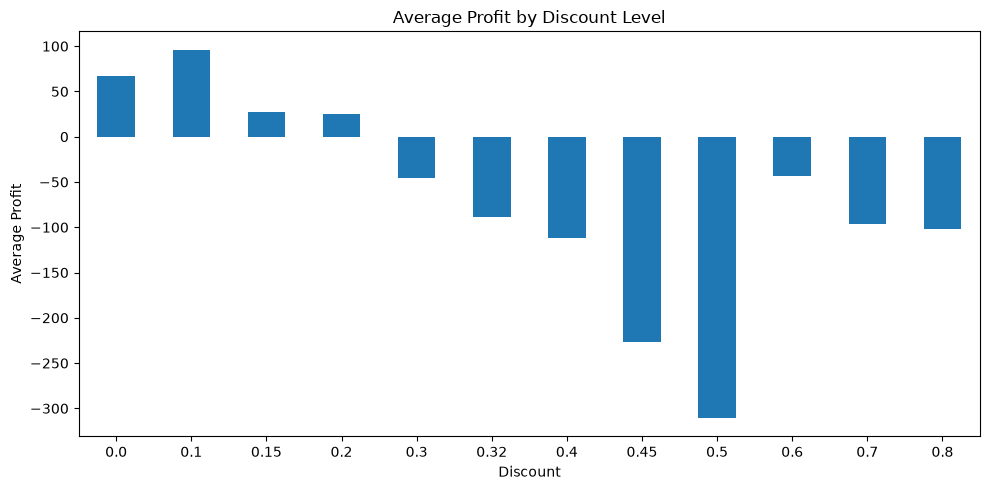

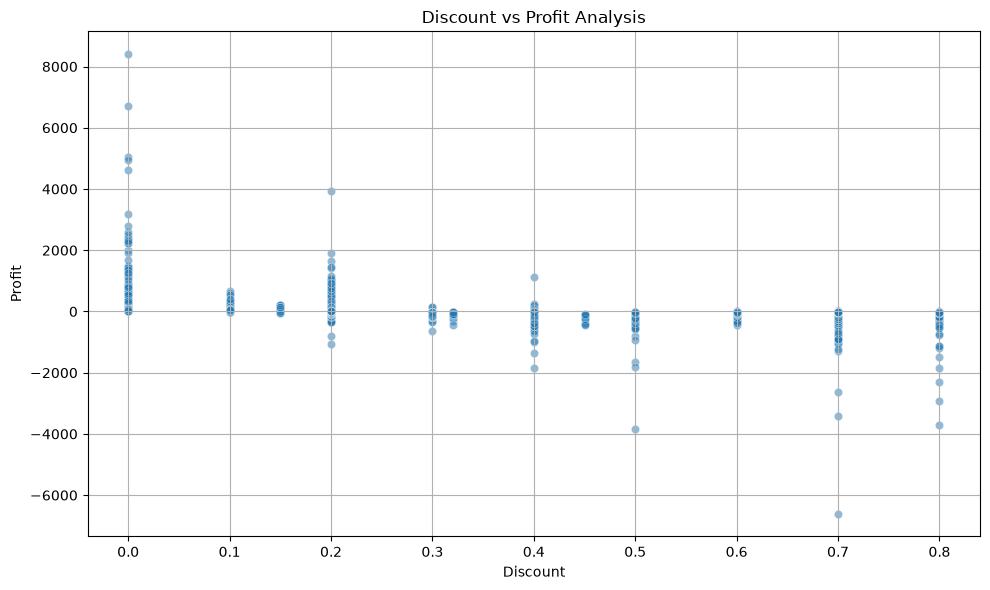

Correlation Matrix:
             Sales  Quantity  Discount    Profit
Sales     1.000000  0.200795 -0.028190  0.479064
Quantity  0.200795  1.000000  0.008623  0.066253
Discount -0.028190  0.008623  1.000000 -0.219487
Profit    0.479064  0.066253 -0.219487  1.000000


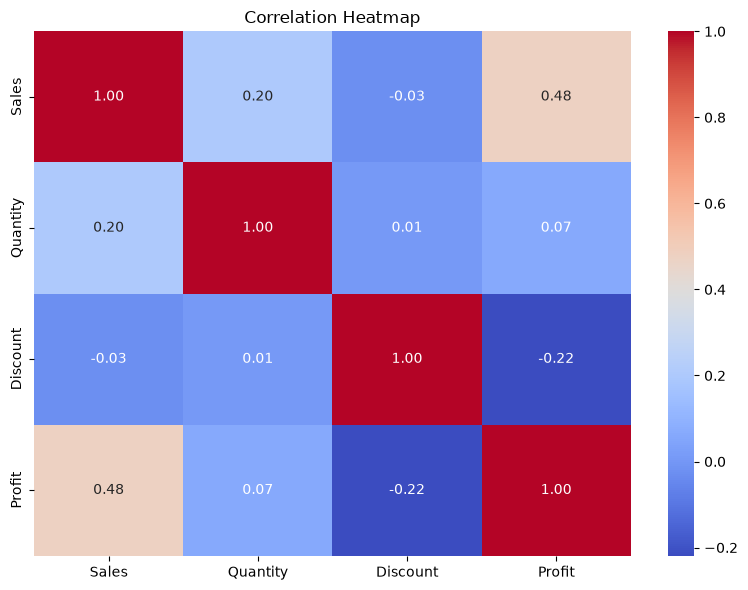

Number of Orders by Region:
Region
West       1611
East       1401
Central    1175
South       822
Name: Order ID, dtype: int64
Sales by Shipping Mode:
Ship Mode
Standard Class    1.358216e+06
Second Class      4.591936e+05
First Class       3.514284e+05
Same Day          1.283631e+05
Name: Sales, dtype: float64
Average Shipping Duration: 3.96 days
Yearly Sales:
Year
2015.0    484247.4981
2016.0    470532.5090
2017.0    609205.5980
2018.0    733215.2552
Name: Sales, dtype: float64


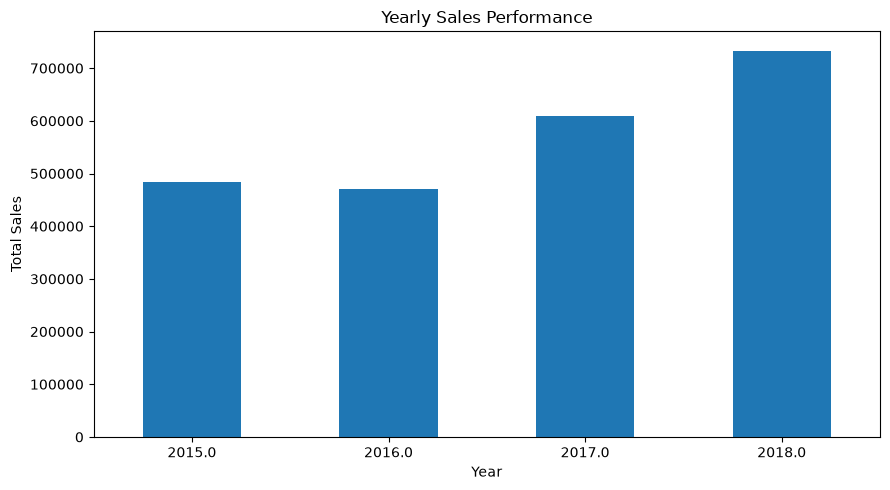

Yearly Profit:
Year
2015.0    49543.9741
2016.0    61618.6037
2017.0    81795.1743
2018.0    93439.2696
Name: Profit, dtype: float64


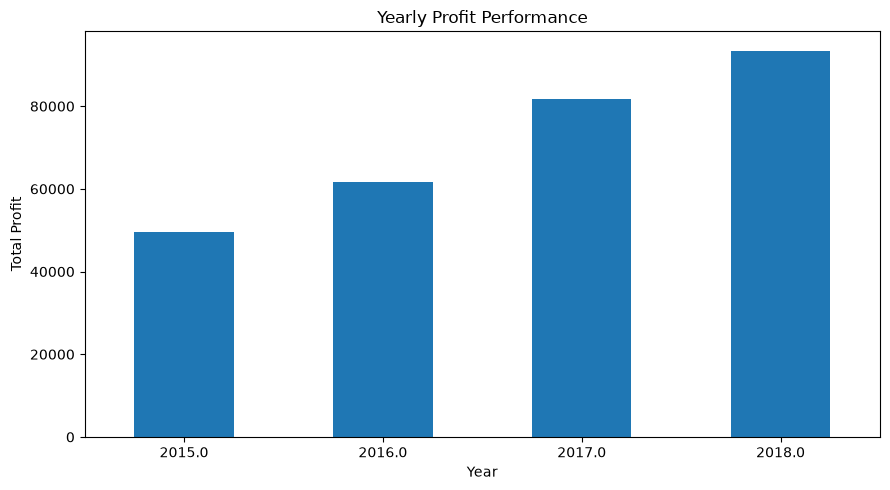

                       Sales       Profit
Category                                 
Furniture        741999.7953   18451.2728
Office Supplies  719047.0320  122490.8008
Technology       836154.0330  145454.9481


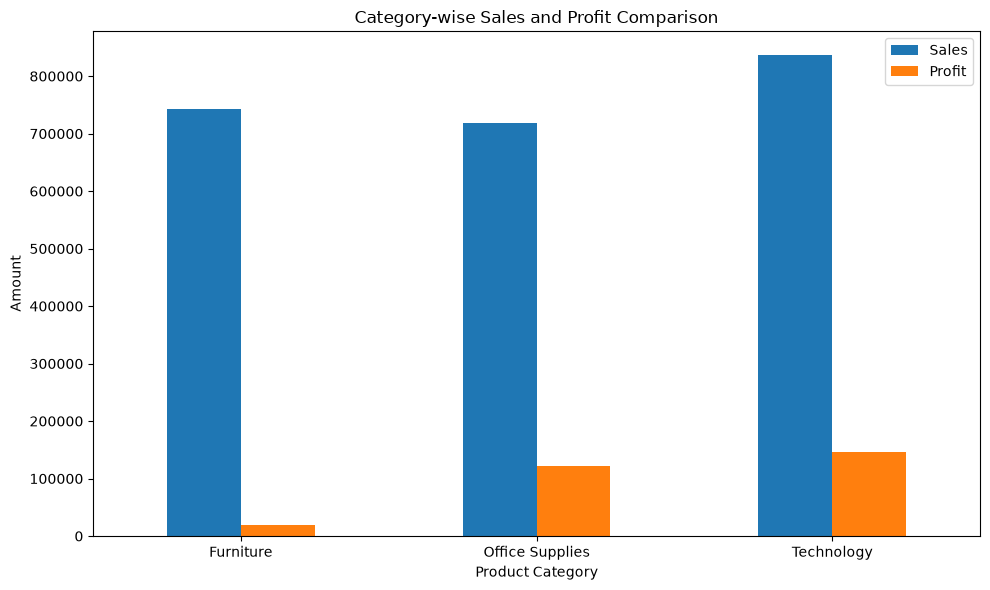

Region-wise Category Sales:


Category,Furniture,Office Supplies,Technology
Region,,,
Central,163797.1638,167026.415,170416.312
East,208291.2040,205516.055,264973.981
South,117298.6840,125651.313,148771.908
West,252612.7435,220853.249,251991.832


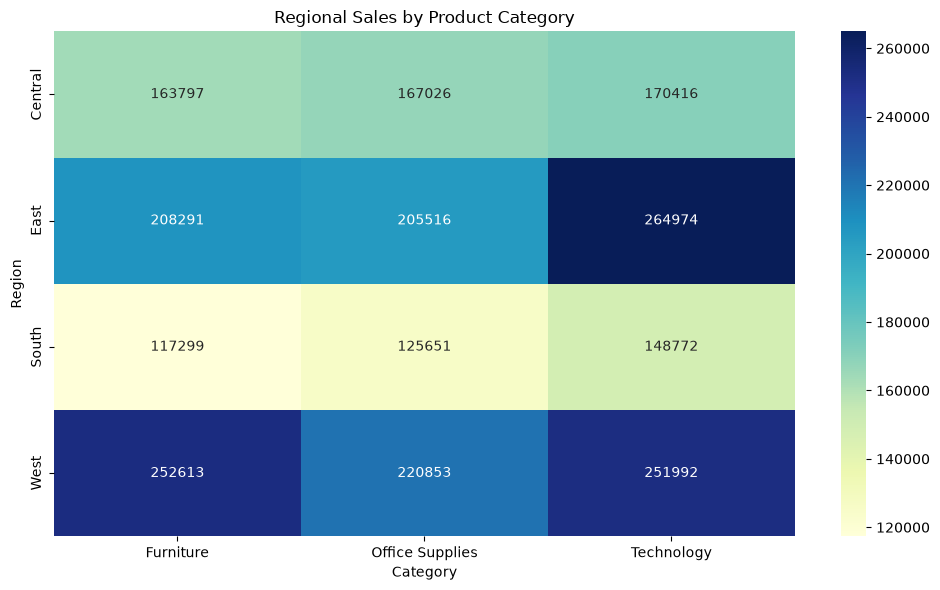

Top 10 Products by Sales:
Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


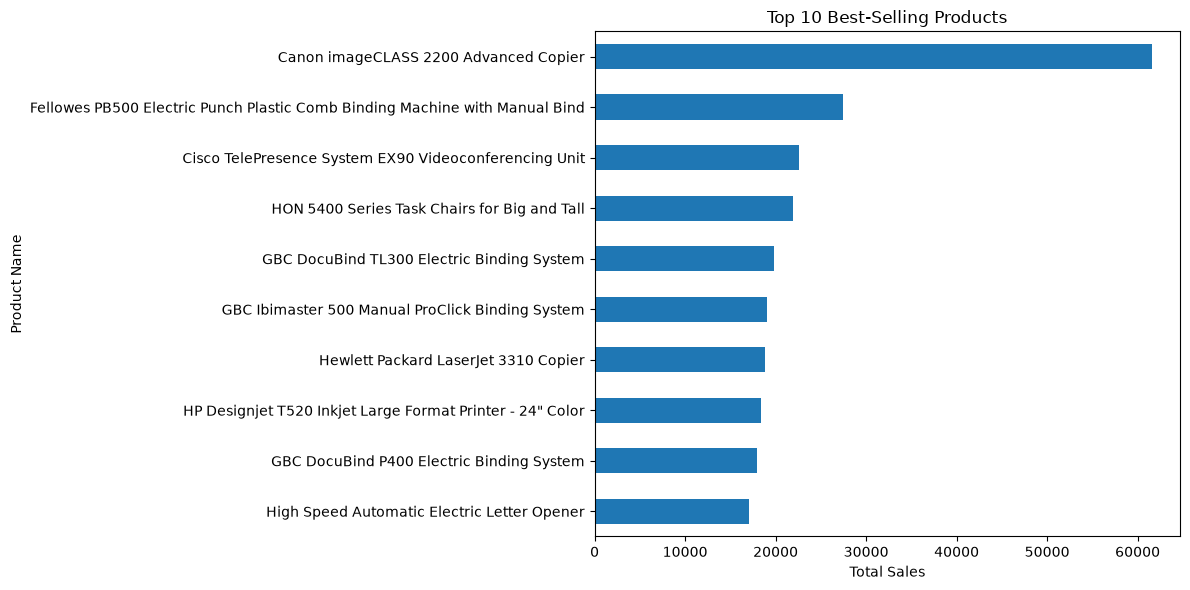

Bottom 10 Products by Profit:
Product Name
Cubify CubeX 3D Printer Double Head Print                           -8879.9704
Lexmark MX611dhe Monochrome Laser Printer                           -4589.9730
Cubify CubeX 3D Printer Triple Head Print                           -3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases            -2876.1156
Bush Advantage Collection Racetrack Conference Table                -1934.3976
GBC DocuBind P400 Electric Binding System                           -1878.1662
Cisco TelePresence System EX90 Videoconferencing Unit               -1811.0784
Martin Yale Chadless Opener Electric Letter Opener                  -1299.1836
Balt Solid Wood Round Tables                                        -1201.0581
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables   -1148.4375
Name: Profit, dtype: float64


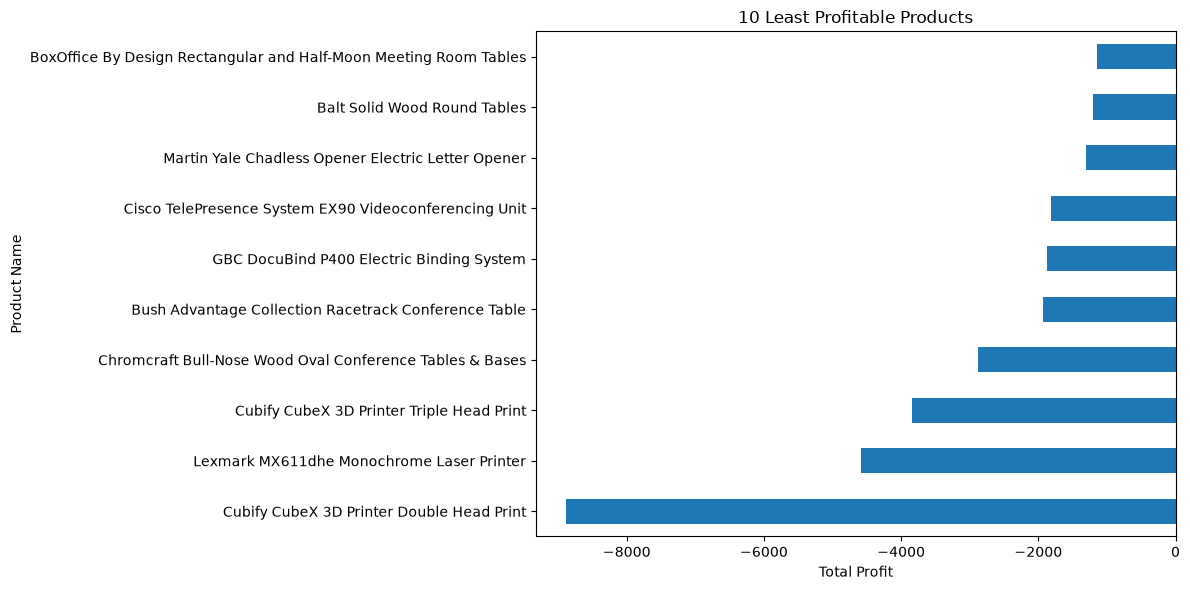

,Total_Sales,Total_Profit,Total_Quantity,Unique_Orders,Unique_Customers,Profit_Margin
Segment,,,,,,
Consumer,1161401.34,134119.21,19521.0,2586,409,11.55
Corporate,706146.37,91979.13,11608.0,1514,236,13.03
Home Office,429653.15,60298.68,6744.0,909,148,14.03


Monthly Seasonal Sales:
Month
January       94924.8356
February      59751.2514
March        205005.4888
April        137762.1286
May          155028.8117
June         152718.6793
July         147238.0970
August       159044.0630
September    307649.9457
October      200322.9847
November     352461.0710
December     325293.5035
Name: Sales, dtype: float64


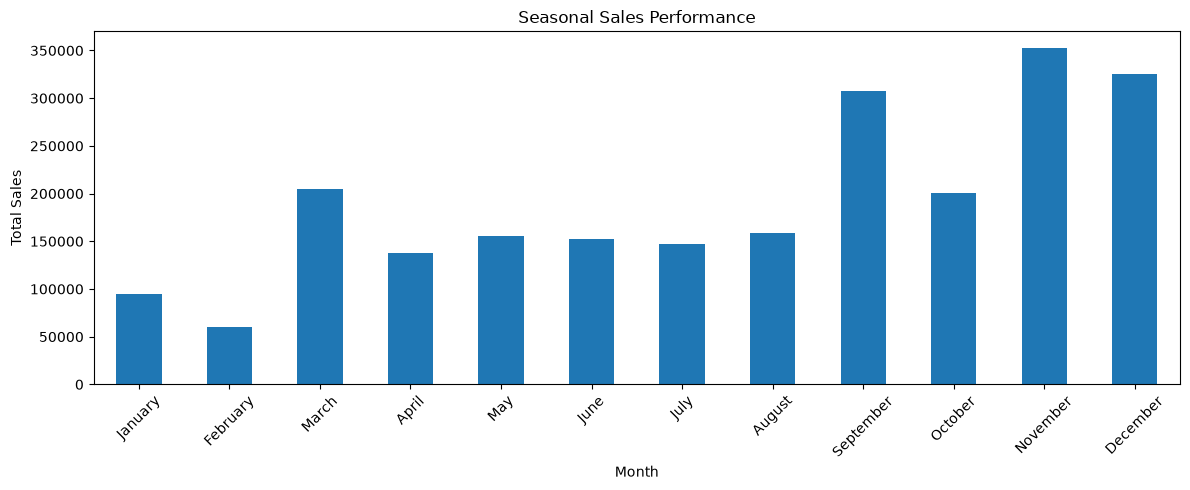

,Total_Sales,Total_Profit,Average_Profit
Discount Range,,,
0–10%,1142277.82,330016.78,67.46
10–20%,792152.89,91756.30,24.74
20–30%,103226.66,-10369.28,-45.68
30–50%,195314.76,-48447.73,-156.28
50–80%,64228.74,-76559.05,-89.44


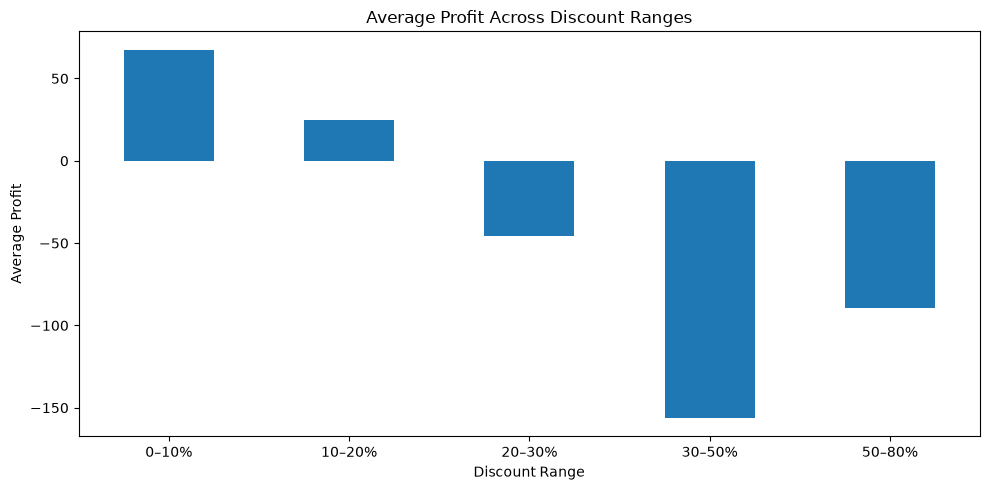

In [11]:
discount_distribution = df['Discount'].value_counts().sort_index()

print("Discount Distribution:")
print(discount_distribution)

discount_profit = df.groupby('Discount')['Profit'].mean()

print("Average Profit by Discount:")
print(discount_profit)

plt.figure(figsize=(10, 5))

discount_profit.plot(kind='bar')

plt.title('Average Profit by Discount Level')
plt.xlabel('Discount')
plt.ylabel('Average Profit')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x='Discount', y='Profit', alpha=0.5)

plt.title('Discount vs Profit Analysis')
plt.xlabel('Discount')
plt.ylabel('Profit')
plt.grid(True)
plt.tight_layout()
plt.show()

numeric_columns = ['Sales', 'Quantity', 'Discount', 'Profit']

correlation = df[numeric_columns].corr()

print("Correlation Matrix:")
print(correlation)

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

region_orders = df.groupby('Region')['Order ID'].nunique().sort_values(ascending=False)

print("Number of Orders by Region:")
print(region_orders)

shipping_sales = df.groupby('Ship Mode')['Sales'].sum().sort_values(ascending=False)

print("Sales by Shipping Mode:")
print(shipping_sales)

df['Shipping Days'] = (df['Ship Date'] - df['Order Date']).dt.days

average_shipping_days = df['Shipping Days'].mean()

print("Average Shipping Duration:", round(average_shipping_days, 2), "days")

kpi_summary = pd.DataFrame({
    'Metric': [
        'Total Sales',
        'Total Profit',
        'Total Quantity Sold',
        'Total Orders',
        'Unique Customers',
        'Average Sales',
        'Average Profit',
        'Profit Margin',
        'Average Shipping Days'
    ],
    'Value': [
        df['Sales'].sum(),
        df['Profit'].sum(),
        df['Quantity'].sum(),
        df['Order ID'].nunique(),
        df['Customer ID'].nunique(),
        df['Sales'].mean(),
        df['Profit'].mean(),
        (df['Profit'].sum() / df['Sales'].sum()) * 100,
        df['Shipping Days'].mean()
    ]
})

kpi_summary

yearly_sales = df.groupby('Year')['Sales'].sum()

print("Yearly Sales:")
print(yearly_sales)

plt.figure(figsize=(9, 5))
yearly_sales.plot(kind='bar')

plt.title('Yearly Sales Performance')
plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

yearly_profit = df.groupby('Year')['Profit'].sum()

print("Yearly Profit:")
print(yearly_profit)

plt.figure(figsize=(9, 5))
yearly_profit.plot(kind='bar')

plt.title('Yearly Profit Performance')
plt.xlabel('Year')
plt.ylabel('Total Profit')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

category_comparison = df.groupby('Category')[['Sales', 'Profit']].sum()

print(category_comparison)

category_comparison.plot(kind='bar', figsize=(10, 6))

plt.title('Category-wise Sales and Profit Comparison')
plt.xlabel('Product Category')
plt.ylabel('Amount')
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

region_category = pd.pivot_table(
    df,
    values='Sales',
    index='Region',
    columns='Category',
    aggfunc='sum'
)

print("Region-wise Category Sales:")
display(region_category)

plt.figure(figsize=(10, 6))

sns.heatmap(
    region_category,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu'
)

plt.title('Regional Sales by Product Category')
plt.tight_layout()
plt.show()

top_products = (
    df.groupby('Product Name')['Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Sales:")
print(top_products)

plt.figure(figsize=(12, 6))

top_products.sort_values().plot(kind='barh')

plt.title('Top 10 Best-Selling Products')
plt.xlabel('Total Sales')
plt.ylabel('Product Name')
plt.tight_layout()
plt.show()

bottom_products = (
    df.groupby('Product Name')['Profit']
    .sum()
    .sort_values()
    .head(10)
)

print("Bottom 10 Products by Profit:")
print(bottom_products)

plt.figure(figsize=(12, 6))

bottom_products.sort_values().plot(kind='barh')

plt.title('10 Least Profitable Products')
plt.xlabel('Total Profit')
plt.ylabel('Product Name')
plt.tight_layout()
plt.show()

customer_report = df.groupby('Segment').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Unique_Orders=('Order ID', 'nunique'),
    Unique_Customers=('Customer ID', 'nunique')
)

customer_report['Profit_Margin'] = (
    customer_report['Total_Profit'] /
    customer_report['Total_Sales'] * 100
)

display(customer_report.round(2))

month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

seasonal_sales = df.groupby('Month')['Sales'].sum()

seasonal_sales = seasonal_sales.reindex(month_order)

print("Monthly Seasonal Sales:")
print(seasonal_sales)

plt.figure(figsize=(12, 5))

seasonal_sales.plot(kind='bar')

plt.title('Seasonal Sales Performance')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

df['Discount Range'] = pd.cut(
    df['Discount'],
    bins=[-0.01, 0.1, 0.2, 0.3, 0.5, 0.8],
    labels=['0–10%', '10–20%', '20–30%', '30–50%', '50–80%']
)

discount_analysis = df.groupby(
    'Discount Range',
    observed=False
).agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Average_Profit=('Profit', 'mean')
)

display(discount_analysis.round(2))

discount_analysis['Average_Profit'].plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Average Profit Across Discount Ranges')
plt.xlabel('Discount Range')
plt.ylabel('Average Profit')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Executive Business Findings

### 1. Technology Drives Profitability
Technology generated the highest category-wise profit of approximately $145,454.95, making it the strongest contributor to overall category profitability.

### 2. Western Region Leads Sales
The West region recorded the highest sales of approximately $725,457.82 and profit of $108,418.45.

### 3. Consumer Segment Generates the Highest Revenue
The Consumer segment contributed approximately $1.16 million in sales and $134,119.21 in profit.

### 4. Higher Discounts Can Reduce Profitability
Discount levels of 30% and above showed negative average profit in the observed discount groups. The business should carefully review its discount strategy.

### 5. November Shows Strong Sales Performance
November 2018 recorded monthly sales of approximately $118,447.83, indicating a strong sales period.

## Business Recommendations

- Focus on profitable technology products.
- Strengthen sales strategies in high-performing regions.
- Maintain customer engagement in the Consumer segment.
- Review high-discount pricing policies.
- Prepare inventory and marketing strategies for peak sales periods.

In [14]:
print("Missing values in each column:")
print(df.isnull().sum())

print("Invalid Order Dates:", df['Order Date'].isna().sum())
print("Invalid Ship Dates:", df['Ship Date'].isna().sum())

print("Duplicate rows:", df.duplicated().sum())
print("Final dataset shape:", df.shape)
display(df.head())
df.info()
df.to_csv("cleaned_superstore_sales.csv", index=False)

print("Cleaned dataset exported successfully!")

before = len(df)

df = df.dropna(subset=['Order Date']).copy()

df.reset_index(drop=True, inplace=True)

after = len(df)

print("Rows before cleaning:", before)
print("Incomplete rows removed:", before - after)
print("Rows after cleaning:", after)
print(df.isnull().sum())
print("Invalid Order Dates:", df['Order Date'].isna().sum())
print("Invalid Ship Dates:", df['Ship Date'].isna().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Final dataset shape:", df.shape)


Missing values in each column:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
Year              0
Month             0
Year-Month        0
Shipping Days     0
Discount Range    0
dtype: int64
Invalid Order Dates: 0
Invalid Ship Dates: 0
Duplicate rows: 0
Final dataset shape: (9994, 26)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Year-Month,Shipping Days,Discount Range
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136,2017.0,November,2017-11,3.0,0–10%
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820,2017.0,November,2017-11,3.0,0–10%
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714,2017.0,June,2017-06,4.0,0–10%
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310,2016.0,October,2016-10,7.0,30–50%
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164,2016.0,October,2016-10,7.0,10–20%


<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 26 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          9994 non-null   str           
 1   Order ID        9994 non-null   str           
 2   Order Date      9994 non-null   datetime64[us]
 3   Ship Date       9994 non-null   datetime64[us]
 4   Ship Mode       9994 non-null   str           
 5   Customer ID     9994 non-null   str           
 6   Customer Name   9994 non-null   str           
 7   Segment         9994 non-null   str           
 8   Country         9994 non-null   str           
 9   City            9994 non-null   str           
 10  State           9994 non-null   str           
 11  Postal Code     9994 non-null   object        
 12  Region          9994 non-null   str           
 13  Product ID      9994 non-null   str           
 14  Category        9994 non-null   str           
 15  Sub-Category   